In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
stock = yf.download("RELIANCE.NS", start="2023-01-01")

stock.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2023-01-02,1175.889648,1177.304802,1163.244669,1164.066352,5316175
2023-01-03,1167.284668,1174.565828,1163.062148,1170.936659,7658932
2023-01-04,1149.709595,1169.110728,1147.632506,1167.261851,9264891
2023-01-05,1147.655151,1157.857903,1143.067373,1151.969076,13637099
2023-01-06,1158.086304,1163.130627,1149.595501,1153.407240,6349597


In [3]:
stock["Daily Return"] = stock["Close"].pct_change()

stock[["Close", "Daily Return"]].head()

Price,Close,Daily Return
Ticker,RELIANCE.NS,
Date,,
2023-01-02,1175.889648,NaN
2023-01-03,1167.284668,-0.007318
2023-01-04,1149.709595,-0.015056
2023-01-05,1147.655151,-0.001787
2023-01-06,1158.086304,0.009089


In [4]:
stock["20_MA"] = stock["Close"].rolling(window=20).mean()
stock["50_MA"] = stock["Close"].rolling(window=50).mean()

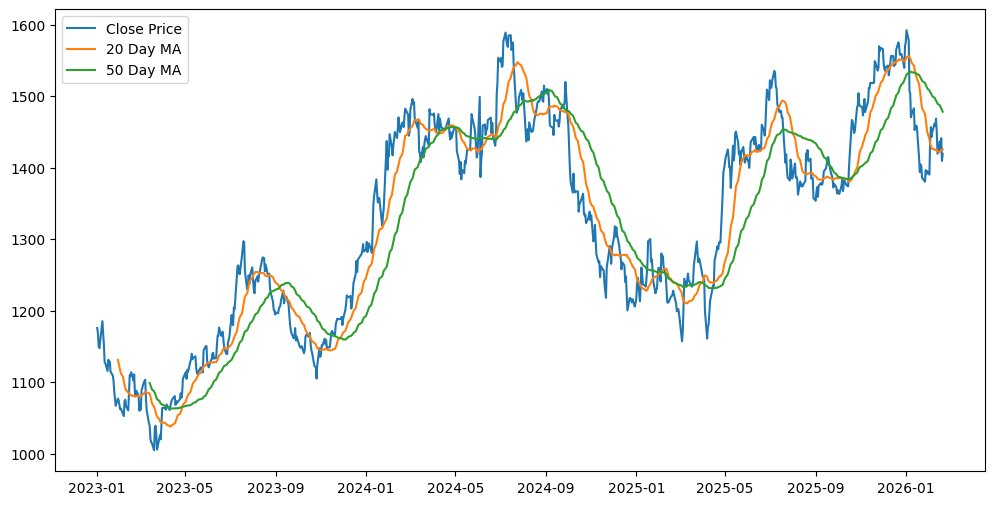

In [5]:
plt.figure(figsize=(12,6))
plt.plot(stock["Close"], label="Close Price")
plt.plot(stock["20_MA"], label="20 Day MA")
plt.plot(stock["50_MA"], label="50 Day MA")
plt.legend()
plt.show()

In [7]:
total_return = (stock["Close"].iloc[-1] / stock["Close"].iloc[0] - 1) * 100
volatility = stock["Daily Return"].std() * 100

print("Total Return:", round(total_return,2), "%")
print("Daily Volatility:", round(volatility,2), "%")

Total Return: Ticker
RELIANCE.NS    20.71
dtype: float64 %
Daily Volatility: 1.27 %


In [8]:
stock["Signal"] = 0
stock.loc[stock["20_MA"] > stock["50_MA"], "Signal"] = 1
stock.loc[stock["20_MA"] < stock["50_MA"], "Signal"] = -1

stock[["Close", "20_MA", "50_MA", "Signal"]].tail()

Price,Close,20_MA,50_MA,Signal
Ticker,RELIANCE.NS,,,
Date,,,,
2026-02-16,1437.099976,1421.864996,1487.512000,-1
2026-02-17,1423.000000,1422.334998,1485.160000,-1
2026-02-18,1441.300049,1424.700000,1483.126001,-1
2026-02-19,1409.500000,1424.945001,1480.728000,-1
2026-02-20,1419.400024,1425.790002,1478.378000,-1


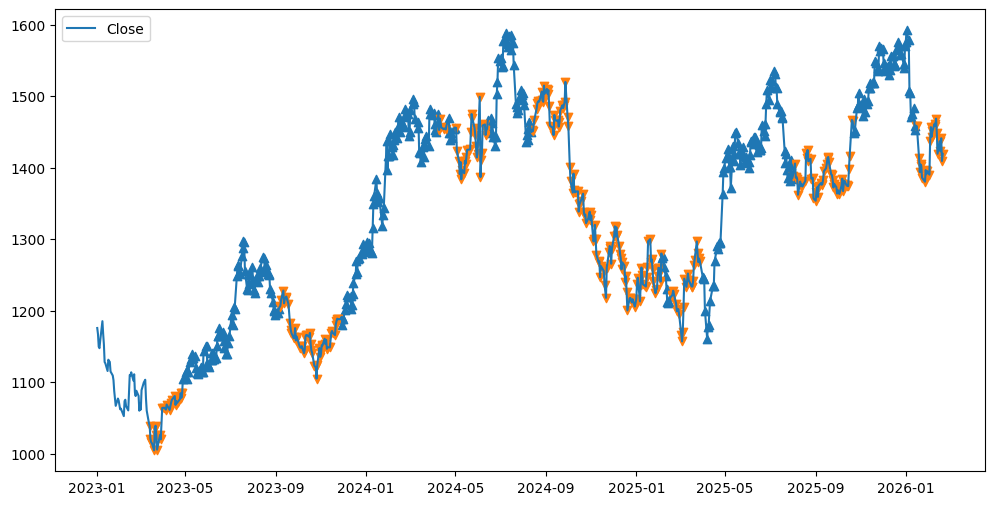

In [9]:
plt.figure(figsize=(12,6))
plt.plot(stock["Close"], label="Close")

buy = stock[stock["Signal"] == 1]
sell = stock[stock["Signal"] == -1]

plt.scatter(buy.index, buy["Close"], marker="^", alpha=1)
plt.scatter(sell.index, sell["Close"], marker="v", alpha=1)

plt.legend()
plt.show()